# Long-time integration of ODEs: why *symplectic* methods matter
*A 5-minute introduction*

**Question.** If we integrate an oscillator for thousands of periods, which method keeps the physics right?

**Model: (damped) harmonic oscillator**, with $y=(q,p)$:
$$
\dot q = p,\qquad \dot p = -\omega^2 q - 2\gamma p
\quad\Longleftrightarrow\quad
\dot y = A y,\quad A=\begin{pmatrix}0 & 1\\ -\omega^2 & -2\gamma\end{pmatrix}.
$$
Energy $H(q,p)=\tfrac12 p^2+\tfrac12\omega^2 q^2$ satisfies
$$\frac{dH}{dt} = -2\gamma p^2 \le 0 .$$
- $\gamma=0$: $H$ is **conserved** and the flow is **area-preserving** (symplectic): $\det e^{tA}=1$.
- $\gamma>0$: $H$ decays, and phase-space area contracts **exactly** by $\det e^{tA}=e^{\operatorname{tr}(A)t}=e^{-2\gamma t}$.

## 1. The methods (step size $h$)

| Method | Update | Type |
|---|---|---|
| Forward Euler (FE) | $y_{n+1}=y_n+hAy_n$ | explicit, order 1 |
| Backward Euler (BE) | $(I-hA)\,y_{n+1}=y_n$ | implicit, order 1 |
| Classical RK4 | 4 stages | explicit, order 4, **not** symplectic |
| Symplectic Euler (SE) | $p_{n+1}=p_n-h(\omega^2q_n+2\gamma p_{n+1}),\;\; q_{n+1}=q_n+hp_{n+1}$ | semi-implicit, order 1, symplectic |
| Implicit midpoint (IM) | $y_{n+1}=y_n+hA\,\tfrac{y_n+y_{n+1}}{2}$ | **symplectic RK** (1-stage Gauss), order 2 |

**Symplectic Runge–Kutta.** An RK method with tableau $(a_{ij},b_i)$ is symplectic iff
$$ b_i a_{ij} + b_j a_{ji} - b_i b_j = 0 \quad \forall i,j. $$
Implicit midpoint: $a_{11}=\tfrac12,\ b_1=1 \Rightarrow \tfrac12+\tfrac12-1=0$ ✓. (Gauss–Legendre RK with $s$ stages: symplectic, order $2s$.)

**Undamped amplification** ($\gamma=0$, per step, for the energy):
FE: $\times(1+h^2\omega^2)$ → energy **grows**; BE: $\times(1+h^2\omega^2)^{-1}$ → energy **decays**; IM: $\times 1$ exactly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def make_A(omega, gamma):
    return np.array([[0.0, 1.0], [-omega**2, -2.0 * gamma]])

def forward_euler(y, h, A, omega, gamma):
    return y + h * A @ y

def backward_euler(y, h, A, omega, gamma):
    return np.linalg.solve(np.eye(2) - h * A, y)

def rk4(y, h, A, omega, gamma):
    k1 = A @ y
    k2 = A @ (y + 0.5 * h * k1)
    k3 = A @ (y + 0.5 * h * k2)
    k4 = A @ (y + h * k3)
    return y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

def symplectic_euler(y, h, A, omega, gamma):
    q, p = y
    p_new = (p - h * omega**2 * q) / (1.0 + 2.0 * h * gamma)   # implicit in p (linear)
    q_new = q + h * p_new
    return np.array([q_new, p_new])

def implicit_midpoint(y, h, A, omega, gamma):
    I = np.eye(2)
    return np.linalg.solve(I - 0.5 * h * A, (I + 0.5 * h * A) @ y)

METHODS = {"Forward Euler": forward_euler, "Backward Euler": backward_euler,
           "RK4": rk4, "Symplectic Euler": symplectic_euler,
           "Implicit midpoint": implicit_midpoint}
COLORS = {"Forward Euler": "tab:blue", "Backward Euler": "tab:orange", "RK4": "tab:green",
          "Symplectic Euler": "tab:red", "Implicit midpoint": "tab:purple"}

def integrate(step, y0, h, T, omega, gamma):
    A = make_A(omega, gamma)
    n = int(round(T / h))
    Y = np.empty((n + 1, 2)); Y[0] = y0
    for k in range(n):
        Y[k + 1] = step(Y[k], h, A, omega, gamma)
    return np.linspace(0, n * h, n + 1), Y

def exact(y0, t, omega, gamma):
    # y(t) = exp(tA) y0 via eigen-decomposition (valid for gamma != omega)
    lam, V = np.linalg.eig(make_A(omega, gamma))
    c = np.linalg.solve(V, y0.astype(complex))
    return np.real((V @ (c[:, None] * np.exp(np.outer(lam, t)))).T)

def energy(Y, omega):
    return 0.5 * Y[:, 1]**2 + 0.5 * omega**2 * Y[:, 0]**2

## 2. Symplectic = area preserving (check $\det$ of the one-step map)
For a linear method $y_{n+1}=M y_n$. Exact: $\det e^{hA}=e^{-2\gamma h}$ (equal to 1 when $\gamma=0$).

In [2]:
omega, h = 1.0, 0.1
for gamma in [0.0, 0.02]:
    A = make_A(omega, gamma)
    print(f"gamma = {gamma}:   exact det = {np.exp(-2*gamma*h):.8f}")
    for name, step in METHODS.items():
        M = np.column_stack([step(e, h, A, omega, gamma) for e in np.eye(2)])
        print(f"   {name:18s} det M = {np.linalg.det(M):.8f}")

gamma = 0.0:   exact det = 1.00000000
   Forward Euler      det M = 1.01000000
   Backward Euler     det M = 0.99009901
   RK4                det M = 0.99999999
   Symplectic Euler   det M = 1.00000000
   Implicit midpoint  det M = 1.00000000
gamma = 0.02:   exact det = 0.99600799
   Forward Euler      det M = 1.00600000
   Backward Euler     det M = 0.98619329
   RK4                det M = 0.99600799
   Symplectic Euler   det M = 0.99601594
   Implicit midpoint  det M = 0.99601792


## 3. Undamped oscillator ($\gamma=0$), very long time: $T=1000$ (≈160 periods), $h=0.1$

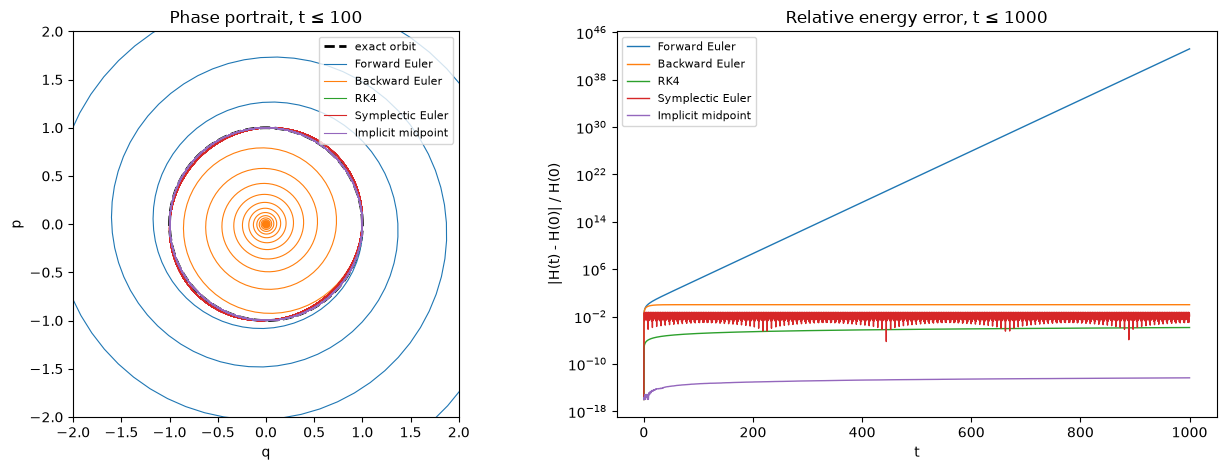

In [3]:
omega, gamma, h, T = 1.0, 0.0, 0.1, 1000.0
y0 = np.array([1.0, 0.0])
res = {name: integrate(step, y0, h, T, omega, gamma) for name, step in METHODS.items()}
H0 = energy(y0[None, :], omega)[0]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
th = np.linspace(0, 2*np.pi, 300)
ax[0].plot(np.cos(th), np.sin(th), "k--", lw=2, label="exact orbit")
for name, (t, Y) in res.items():
    m = t <= 100                              # first ~16 periods for readability
    ax[0].plot(Y[m, 0], Y[m, 1], lw=0.8, color=COLORS[name], label=name)
ax[0].set(xlim=(-2, 2), ylim=(-2, 2), aspect="equal", xlabel="q", ylabel="p",
          title="Phase portrait, t ≤ 100")
ax[0].legend(fontsize=8, loc="upper right")

for name, (t, Y) in res.items():
    err = np.abs(energy(Y, omega) - H0) / H0
    ax[1].semilogy(t, np.maximum(err, 1e-16), lw=1, color=COLORS[name], label=name)
ax[1].set(xlabel="t", ylabel="|H(t) - H(0)| / H(0)", title="Relative energy error, t ≤ 1000")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Video: the phase portrait in motion ($\gamma=0$)
Each panel: a moving point $(q_n,p_n)$ with its trail; the dashed circle is the exact orbit $H=H_0$.

In [4]:
from matplotlib import animation
from IPython.display import HTML

omega, gamma, h, T_anim = 1.0, 0.0, 0.1, 60.0
y0 = np.array([1.0, 0.0])
anim_res = {name: integrate(step, y0, h, T_anim, omega, gamma) for name, step in METHODS.items()}
n_steps = len(anim_res["RK4"][0])
frames = range(0, n_steps, 6)                 # every 6th step -> 100 frames

fig, axes = plt.subplots(1, len(METHODS), figsize=(16, 3.6), dpi=70)
th = np.linspace(0, 2*np.pi, 200)
trails, dots = {}, {}
for ax, name in zip(axes, METHODS):
    ax.plot(np.cos(th), np.sin(th), "k--", lw=1)
    trails[name], = ax.plot([], [], lw=1, color=COLORS[name])
    dots[name], = ax.plot([], [], "o", ms=7, color=COLORS[name])
    ax.set(xlim=(-2.2, 2.2), ylim=(-2.2, 2.2), aspect="equal", title=name, xlabel="q")
    ax.set_xticks([]); ax.set_yticks([])
axes[0].set_ylabel("p")
time_txt = fig.suptitle("")

def update(k):
    for name, (t, Y) in anim_res.items():
        trails[name].set_data(Y[:k+1, 0], Y[:k+1, 1])
        dots[name].set_data([Y[k, 0]], [Y[k, 1]])
    time_txt.set_text(f"t = {anim_res['RK4'][0][k]:.1f}")
    return list(trails.values()) + list(dots.values()) + [time_txt]

anim = animation.FuncAnimation(fig, update, frames=frames, interval=60, blit=False)
plt.rcParams["animation.embed_limit"] = 50    # MB
plt.close(fig)                                # show only the video, not a static frame
HTML(anim.to_jshtml())

**Observations.**
- FE spirals **out** (energy blows up like $(1+h^2)^n$), BE spirals **in** (artificial damping; relative error saturates at 1 as $H\to 0$).
- RK4 is very accurate per step, but its energy error **drifts linearly** in $t$ — it never stops growing.
- Symplectic Euler: energy error is $O(h)$ but **bounded for all time** (it exactly conserves a nearby "modified energy").
- Implicit midpoint conserves the quadratic energy $H$ **to round-off**.

## 4. Damped oscillator ($\gamma=0.02$), $T=300$, $h=0.1$
Does the method reproduce the **correct decay rate**?

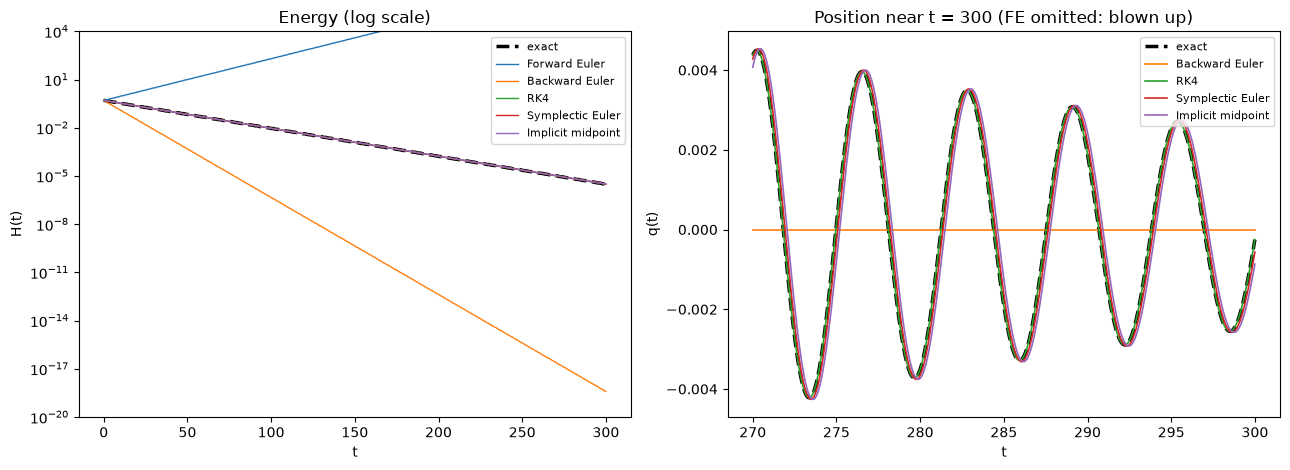

method               H(T) numerical   H(T) exact
Forward Euler             3.164e+07    3.085e-06
Backward Euler            3.832e-19    3.085e-06
RK4                       3.085e-06    3.085e-06
Symplectic Euler          3.105e-06    3.085e-06
Implicit midpoint         3.207e-06    3.085e-06


In [5]:
omega, gamma, h, T = 1.0, 0.02, 0.1, 300.0
y0 = np.array([1.0, 0.0])
res = {name: integrate(step, y0, h, T, omega, gamma) for name, step in METHODS.items()}
t_ex = res["RK4"][0]
Y_ex = exact(y0, t_ex, omega, gamma)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].semilogy(t_ex, energy(Y_ex, omega), "k--", lw=2.5, label="exact")
for name, (t, Y) in res.items():
    ax[0].semilogy(t, energy(Y, omega), lw=1, color=COLORS[name], label=name)
ax[0].set(xlabel="t", ylabel="H(t)", title="Energy (log scale)", ylim=(1e-20, 1e4))
ax[0].legend(fontsize=8)

m = t_ex >= T - 30                                    # zoom on the end of the run
ax[1].plot(t_ex[m], Y_ex[m, 0], "k--", lw=2.5, label="exact")
for name in ["Backward Euler", "RK4", "Symplectic Euler", "Implicit midpoint"]:
    t, Y = res[name]
    ax[1].plot(t[m], Y[m, 0], lw=1.2, color=COLORS[name], label=name)
ax[1].set(xlabel="t", ylabel="q(t)", title=f"Position near t = {T:.0f} (FE omitted: blown up)")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'method':18s} {'H(T) numerical':>16s} {'H(T) exact':>12s}")
for name, (t, Y) in res.items():
    print(f"{name:18s} {energy(Y, omega)[-1]:16.3e} {energy(Y_ex, omega)[-1]:12.3e}")

**Observations.**
- FE: numerical anti-damping $h^2\omega^2$ beats physical damping $2\gamma h$ → energy **grows** although the true system loses energy.
- BE: numerical damping is added to physical damping → decays **far too fast** (wrong physics, looks "stable").
- Symplectic Euler / implicit midpoint: contract phase area at (almost) the exact rate $e^{-2\gamma h}$ (see §2) and follow the true decay. Small remaining errors are mainly **phase** errors, not amplitude errors.
- RK4 is also accurate here: at this $h$ its tiny per-step drift ($\det M\approx e^{-2\gamma h}$ to 8 digits) is invisible next to physical damping. Its weakness is the *unbounded* drift in §3, which matters for (nearly) conservative systems over very long times.

## Take-away
> For long-time simulation, *structure preservation* (symplecticity, energy behaviour) matters more than the local order.
> Symplectic integrators (symplectic Euler, Störmer–Verlet, Gauss–Legendre RK) give **bounded** energy error over exponentially long times;
> non-symplectic methods (FE, BE, even RK4) accumulate **systematic drift**.

*Reference:* E. Hairer, C. Lubich, G. Wanner, *Geometric Numerical Integration*, Springer, 2nd ed., 2006.